In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, SimpleRNN, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


In [3]:
from google.colab import files
uploaded = files.upload()


Saving TSLA.csv to TSLA.csv


In [4]:
df = pd.read_csv("TSLA.csv")
df.head()


,Date,Open,High,Low,Close,Adj Close,Volume
0,2010-06-29,19.000000,25.00,17.540001,23.889999,23.889999,18766300
1,2010-06-30,25.790001,30.42,23.299999,23.830000,23.830000,17187100
2,2010-07-01,25.000000,25.92,20.270000,21.959999,21.959999,8218800
3,2010-07-02,23.000000,23.10,18.709999,19.200001,19.200001,5139800
4,2010-07-06,20.000000,20.00,15.830000,16.110001,16.110001,6866900


In [5]:
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

df = df[['Adj Close']]
df.fillna(method='ffill', inplace=True)


/tmp/ipython-input-184234886.py:5: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)


In [6]:
scaler = MinMaxScaler()
scaled = scaler.fit_transform(df)


In [7]:
def create_sequences(data, window, horizon):
    X, y = [], []
    for i in range(len(data) - window - horizon):
        X.append(data[i:i+window])
        y.append(data[i+window+horizon-1])
    return np.array(X), np.array(y)

WINDOW = 60
HORIZON = 1   # change later for 5 and 10


In [8]:
train_size = int(len(scaled)*0.8)
train, test = scaled[:train_size], scaled[train_size:]

X_train, y_train = create_sequences(train, WINDOW, HORIZON)
X_test, y_test = create_sequences(test, WINDOW, HORIZON)


In [9]:
model_rnn = Sequential([
    SimpleRNN(64, input_shape=(WINDOW,1)),
    Dropout(0.2),
    Dense(1)
])

model_rnn.compile(optimizer='adam', loss='mse')


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [10]:
es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history_rnn = model_rnn.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=40,
    batch_size=32,
    callbacks=[es]
)


Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0095 - val_loss: 0.0025
Epoch 2/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0012 - val_loss: 0.0018
Epoch 3/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 7.4064e-04 - val_loss: 7.1921e-04
Epoch 4/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.8196e-04 - val_loss: 3.0152e-04
Epoch 5/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 4.3000e-04 - val_loss: 7.0453e-04
Epoch 6/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 4.7882e-04 - val_loss: 4.1321e-04
Epoch 7/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 3.8878e-04 - val_loss: 3.6418e-04
Epoch 8/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 4.0156e-04 - val_loss: 4.0256e-04
Epoch 9/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 3.3743e-04 - val_loss: 2.9963e-04
Epoch 10/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3.4584e-04 - val_loss: 1.7676e-04
Epoch 11/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 3.5904e-04 - val_loss: 1.8266e

In [11]:
model_lstm = Sequential([
    LSTM(64, input_shape=(WINDOW,1)),
    Dropout(0.2),
    Dense(1)
])

model_lstm.compile(optimizer='adam', loss='mse')


In [12]:
history_lstm = model_lstm.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=40,
    batch_size=32,
    callbacks=[es]
)


Epoch 1/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0060 - val_loss: 3.1642e-04
Epoch 2/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 4.0908e-04 - val_loss: 6.2096e-04
Epoch 3/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 4.4234e-04 - val_loss: 2.9178e-04
Epoch 4/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 4.3160e-04 - val_loss: 2.4997e-04
Epoch 5/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 3.4791e-04 - val_loss: 2.5224e-04
Epoch 6/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 2.9728e-04 - val_loss: 2.6366e-04
Epoch 7/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 2.6550e-04 - val_loss: 4.4387e-04
Epoch 8/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 2.8289e-04 - val_loss: 2.6861e-04
Epoch 9/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 2.3719e-04 - val_loss: 2.2196e-04
Epoch 10/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 2.4976e-04 - val_loss: 2.4025e-04
Epoch 11/40
47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 2.3785e-04 - 

In [13]:
pred_rnn = model_rnn.predict(X_test)
pred_lstm = model_lstm.predict(X_test)

pred_rnn = scaler.inverse_transform(pred_rnn)
pred_lstm = scaler.inverse_transform(pred_lstm)
actual = scaler.inverse_transform(y_test)


14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


In [14]:
def rmse(a,b):
    return np.sqrt(mean_squared_error(a,b))

print("SimpleRNN RMSE:", rmse(actual,pred_rnn))
print("LSTM RMSE:", rmse(actual,pred_lstm))


SimpleRNN RMSE: 12.99636930858615
LSTM RMSE: 18.790811164349098


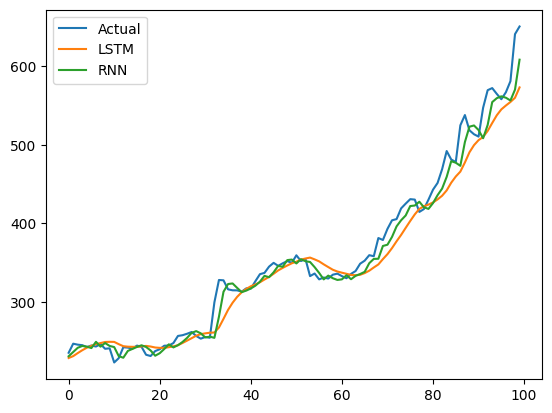

In [15]:
plt.plot(actual[-100:], label="Actual")
plt.plot(pred_lstm[-100:], label="LSTM")
plt.plot(pred_rnn[-100:], label="RNN")
plt.legend()
plt.show()


In [16]:
model_lstm.save("lstm_model.h5")
model_rnn.save("rnn_model.h5")


In [17]:
import joblib
joblib.dump(scaler, "scaler.pkl")


['scaler.pkl']

In [18]:
from google.colab import files
files.download("lstm_model.h5")
files.download("rnn_model.h5")
files.download("scaler.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>